# 04 · Expert bias

**Question.** How much of the classification and transfer error comes from the catalog labels rather than from the classifier? Four parts:

1. **Confident learning in every system (own criterion):** with out-of-sample probabilities (5-fold XGBoost), cleanlab flags the events whose analyst label is unlikely given the rest of the same catalog. Unsupervised clustering (HDBSCAN, tuned by DBCV with Optuna) is compared with the labels.
2. **Confident learning across datasets:** the labels of a target are judged with the criterion learned on another dataset (source) and compared with the target's own criterion. LP and VT act as a control; HB is compared among Hudson, Copahue, Ruiz-Olleta and Ruiz-Bis.
3. **Hudson in detail:** suspects by class, suggested class and the manual review of a sample.
4. **HB/LP criterion at the onset:** fraction of high-frequency energy at the start of the event (`HF_onset`) by SNR quartile, HB versus LP.

Classes with at least 50 events per system; in the large OVDAS catalogs (Villarrica, Nevados de Chillán) each class is capped at 20,000 random events. Everything is shown by system. Reads only `../resultados/` (aggregated values; the manual-review table has ~200 Hudson events).


In [1]:
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%config InlineBackend.figure_format = "png"
plt.rcParams.update({"figure.dpi": 80, "savefig.dpi": 80, "font.size": 9})
pd.set_option("display.width", 160, "display.max_columns", 30)
DATOS, RES = Path("../datos"), Path("../resultados")

# English display names for the systems (the data files keep the Spanish names)
SYSTEM_EN = {"Hawái": "Hawai`i", "Norte de California": "Northern California",
             "Nevados de Chillan": "Nevados de Chillán", "Decepcion": "Deception Island",
             "Decepcion95": "Deception Island 1995", "Decepcion09": "Deception Island 2009",
             "Popocatepetl": "Popocatépetl"}

def en(df, cols=("sistema", "fuente", "destino")):
    """Replace system names by their English display names in the given columns."""
    df = df.copy()
    for c in cols:
        if c in df:
            df[c] = df[c].replace(SYSTEM_EN)
    return df

## 1. Confident learning in every system (own criterion)

Fraction of each analyst class flagged as a suspect label (XGBoost, out-of-sample probabilities). Blank: class absent or with fewer than 50 events.

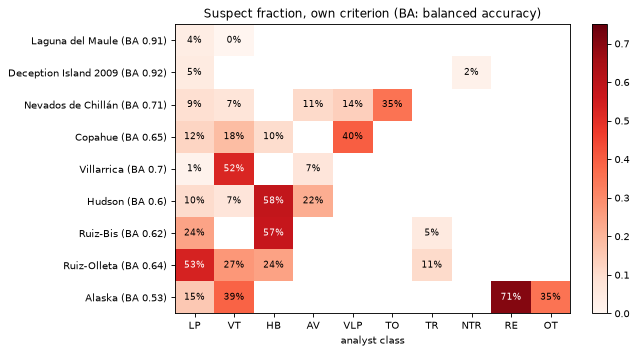

In [2]:
import glob
CLASES = ["LP", "VT", "HB", "AV", "VLP", "TO", "TR", "NTR", "RE", "OT"]
NOMBRE = {"hudson": "Hudson", "copahue": "Copahue", "villarrica": "Villarrica",
          "laguna_del_maule": "Laguna del Maule", "nevados_de_chillan": "Nevados de Chillán",
          "ruiz-olleta": "Ruiz-Olleta", "ruiz-bis": "Ruiz-Bis", "alaska": "Alaska",
          "decepcion09": "Deception Island 2009"}
partes = []
for f in sorted(RES.glob("sesgo_experto_*_cleanlab_por_clase.csv")):
    s = f.name.removeprefix("sesgo_experto_").removesuffix("_cleanlab_por_clase.csv")
    partes.append(pd.read_csv(f).assign(sistema=NOMBRE.get(s, s)))
cls = pd.concat(partes)
x = cls[cls.modelo == "xgb"]
m = x.pivot_table(index="sistema", columns="clase", values="frac_sospechosos")
m = m[[c for c in CLASES if c in m.columns]]
m = m.loc[m.mean(axis=1).sort_values().index]
ba = x.groupby("sistema").exactitud_balanceada_modelo.first().round(2)

fig, ax = plt.subplots(figsize=(8, 4.5))
im = ax.imshow(m.to_numpy(), cmap="Reds", vmin=0, vmax=0.75, aspect="auto")
for i in range(m.shape[0]):
    for j in range(m.shape[1]):
        v = m.iat[i, j]
        if np.isfinite(v):
            ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=8,
                    color="white" if v > 0.45 else "black")
ax.set_xticks(range(m.shape[1]), m.columns)
ax.set_yticks(range(m.shape[0]), [f"{s} (BA {ba[s]})" for s in m.index])
ax.set_xlabel("analyst class"); ax.set_title("Suspect fraction, own criterion (BA: balanced accuracy)")
fig.colorbar(im, ax=ax, fraction=0.04)
fig.tight_layout()

### Unsupervised clustering versus the labels

HDBSCAN on the 16 descriptors (PCA, 90 % of the variance), parameters chosen by DBCV without the labels. `dbcv_etiquetas_experto` is the DBCV of the analyst labels in the same space: negative values mean the classes do not form dense, separated groups.

In [3]:
partes = []
for f in sorted(RES.glob("sesgo_experto_*_agrupamiento.csv")):
    partes.append(pd.read_csv(f))
ag = en(pd.concat(partes))
ag[(ag.metodo == "HDBSCAN") & (ag.representacion == "PCA16")][
    ["sistema", "n_sub", "n_grupos", "frac_ruido", "dbcv", "dbcv_etiquetas_experto", "ARI_todos", "NMI_todos"]
].round(3).set_index("sistema")

,n_sub,n_grupos,frac_ruido,dbcv,dbcv_etiquetas_experto,ARI_todos,NMI_todos
sistema,,,,,,,
Alaska,1395,2,0.267,0.107,-0.851,0.006,0.029
Copahue,4000,2,0.133,0.245,-0.812,0.037,0.033
Deception Island 2009,610,2,0.908,0.033,-0.764,-0.069,0.047
Hudson,4000,2,0.175,0.327,-0.737,0.023,0.050
Laguna del Maule,4000,2,0.801,0.076,-0.831,-0.025,0.012
Nevados de Chillán,4000,2,0.420,0.146,-0.758,0.082,0.081
Ruiz-Bis,493,2,0.781,-0.001,-0.816,-0.009,0.121
Ruiz-Olleta,1031,2,0.502,0.042,-0.831,0.019,0.034
Villarrica,4000,2,0.040,0.266,-0.719,-0.053,0.081


## 2. Confident learning across datasets

For each source → target pair with at least two shared classes among LP, VT and HB (≥ 50 events in both): XGBoost trained on up to 1,000 events per class of the source predicts up to 2,000 per class of the target; cleanlab flags the target labels that disagree with that criterion. *Own* is the same with out-of-sample probabilities of the target itself. Points: median over sources of the mean over 3 repetitions. Above the diagonal, the other dataset flags more than the target's own criterion.

criterio,destino,clases,clase,fuente,propio
0,Alaska,LP-VT,LP,0.182,0.123
1,Alaska,LP-VT,VT,0.159,0.123
2,Cascade,LP-VT,LP,0.065,0.069
3,Cascade,LP-VT,VT,0.058,0.047
4,Copahue,HB-LP,HB,0.537,0.104
5,Copahue,HB-LP,LP,0.465,0.146
6,Copahue,HB-LP-VT,HB,0.527,0.181
7,Copahue,HB-LP-VT,LP,0.328,0.172
8,Copahue,HB-LP-VT,VT,0.382,0.141
9,Copahue,LP-VT,LP,0.088,0.044


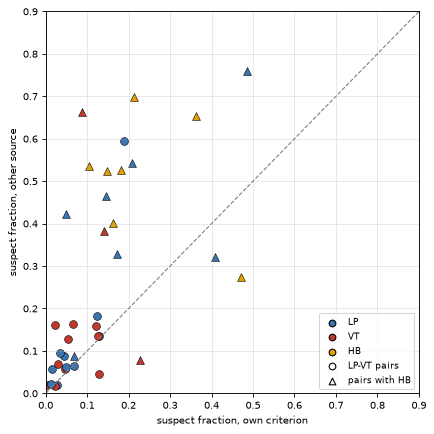

In [4]:
pr = pd.read_csv(RES / "sesgo_entre_datasets_pares.csv")
r = (pr.groupby(["destino", "clases", "clase", "criterio", "fuente"]).frac_sospechosos.mean()
     .groupby(["destino", "clases", "clase", "criterio"]).median().unstack("criterio").reset_index())
r = en(r)
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.plot([0, 1], [0, 1], "--", color="0.5", lw=1)
COL3 = {"LP": "#3b75af", "VT": "#c0392b", "HB": "#e69f00"}
for _, f in r.iterrows():
    ax.scatter(f.propio, f.fuente, marker="o" if f.clases == "LP-VT" else "^", s=50,
               color=COL3[f.clase], edgecolor="k", lw=.5)
for c, col in COL3.items():
    ax.scatter([], [], color=col, edgecolor="k", label=c)
ax.scatter([], [], marker="o", color="w", edgecolor="k", label="LP-VT pairs")
ax.scatter([], [], marker="^", color="w", edgecolor="k", label="pairs with HB")
ax.legend(fontsize=8, loc="lower right"); ax.set_xlim(0, .9); ax.set_ylim(0, .9); ax.grid(alpha=.3)
ax.set_xlabel("suspect fraction, own criterion"); ax.set_ylabel("suspect fraction, other source")
fig.tight_layout()
r.round(3)

### Pairs with HB: suspect fraction and suggested class, per source

Mean over repetitions; `sugiere_*` counts the flagged events of the class by the class the source model suggests.

In [5]:
h = en(pr[pr.clases.str.contains("HB") & (pr.criterio == "fuente")])
h.groupby(["destino", "fuente", "clases", "clase"])[
    ["n", "recall", "frac_sospechosos", "sugiere_HB", "sugiere_LP", "sugiere_VT"]].mean().round(2)

n  recall  frac_sospechosos  sugiere_HB  sugiere_LP  sugiere_VT
destino     fuente      clases   clase                                                                      
Copahue     Hudson      HB-LP-VT HB     2000.0    0.07              0.81        0.00      285.67     1329.33
                                 LP     2000.0    0.54              0.37      253.33        0.00      490.33
                                 VT     2000.0    0.94              0.06       47.67       65.67        0.00
            Ruiz-Bis    HB-LP    HB     2000.0    0.45              0.54        0.00     1073.67         NaN
                                 LP     2000.0    0.54              0.46      929.67        0.00         NaN
            Ruiz-Olleta HB-LP-VT HB     2000.0    0.72              0.25        0.00      419.00       72.67
                                 LP     2000.0    0.65              0.28      525.00        0.00       41.67
                                 VT     2000.0    0.18              0.71     1175.67      240.00        0.00
Hudson      Copahue     HB-LP-VT HB      478.0    0.11              0.69        0.00      264.67       64.00
                                 LP     2000.0    0.96              0.04       63.33        0.00       22.00
                                 VT     2000.0    0.44              0.45      567.33      333.67        0.00
            Ruiz-Bis    HB-LP    HB      478.0    0.60              0.40        0.00      191.67         NaN
                                 LP     2000.0    0.49              0.42      843.00        0.00         NaN
            Ruiz-Olleta HB-LP-VT HB      478.0    0.26              0.62        0.00      295.67        0.67
                                 LP     2000.0    0.87              0.13      253.00        0.00       14.33
                                 VT     2000.0    0.06              0.87     1090.67      658.00        0.00
Ruiz-Bis    Copahue     HB-LP    HB       63.0    0.96              0.04        0.00        2.67         NaN
                                 LP      139.0    0.02              0.84      117.00        0.00         NaN
            Hudson      HB-LP    HB       63.0    0.38              0.54        0.00       34.33         NaN
                                 LP      139.0    0.76              0.24       33.00        0.00         NaN
            Ruiz-Olleta HB-LP    HB       63.0    0.72              0.28        0.00       17.33         NaN
                                 LP      139.0    0.34              0.54       75.33        0.00         NaN
Ruiz-Olleta Copahue     HB-LP-VT HB      357.0    0.29              0.56        0.00       14.67      184.67
                                 LP      142.0    0.12              0.81       36.33        0.00       78.33
                                 VT      172.0    0.86              0.14       23.67        0.33        0.00
            Hudson      HB-LP-VT HB      357.0    0.05              0.84        0.00       23.00      277.00
                                 LP      142.0    0.14              0.71        8.33        0.00       92.67
                                 VT      172.0    0.98              0.02        1.33        1.67        0.00
            Ruiz-Bis    HB-LP    HB      357.0    0.40              0.52        0.00      187.00         NaN
                                 LP      142.0    0.68              0.32       45.67        0.00         NaN

## 3. Hudson in detail: suspects by class

In [6]:
cl = pd.read_csv(RES / "sesgo_experto_hudson_cleanlab_por_clase.csv")
cl[["modelo", "clase", "n", "n_sospechosos", "frac_sospechosos", "snr_mediana_sospechosos",
    "snr_mediana_resto", "sugiere_AV", "sugiere_HB", "sugiere_LP", "sugiere_VT"]].round(3)

,modelo,clase,n,n_sospechosos,frac_sospechosos,snr_mediana_sospechosos,snr_mediana_resto,sugiere_AV,sugiere_HB,sugiere_LP,sugiere_VT
0,xgb,AV,7682,1684,0.219,11.393,13.791,0,6,840,838
1,xgb,HB,483,281,0.582,20.036,20.596,82,0,54,145
2,xgb,LP,10940,1125,0.103,9.813,11.089,875,17,0,233
3,xgb,VT,15035,1022,0.068,10.350,6.992,763,17,242,0
4,logreg,AV,7682,2498,0.325,12.028,13.768,0,0,952,1546
5,logreg,HB,483,327,0.677,20.426,20.120,102,0,97,128
6,logreg,LP,10940,1228,0.112,9.793,11.115,836,0,0,392
7,logreg,VT,15035,1417,0.094,10.027,6.992,1085,2,330,0


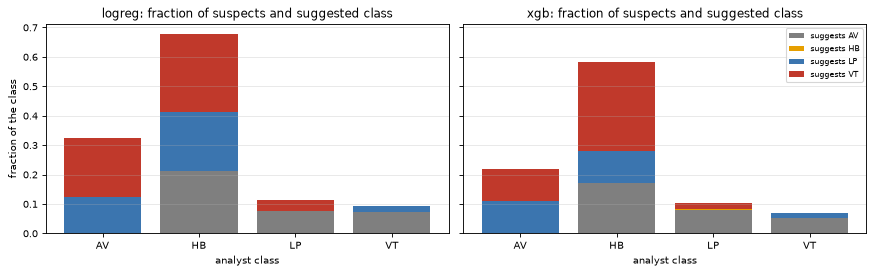

In [7]:
COLOR = {"AV": "#7f7f7f", "HB": "#e69f00", "LP": "#3b75af", "VT": "#c0392b"}
fig, ejes = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
for ax, (mod, g) in zip(ejes, cl.groupby("modelo")):
    g = g.set_index("clase")
    base = np.zeros(len(g))
    for c in ["AV", "HB", "LP", "VT"]:
        v = g[f"sugiere_{c}"] / g.n
        ax.bar(g.index, v, bottom=base, color=COLOR[c], label=f"suggests {c}")
        base += v.values
    ax.set_title(f"{mod}: fraction of suspects and suggested class")
    ax.set_xlabel("analyst class"); ax.grid(axis="y", alpha=.3)
ejes[0].set_ylabel("fraction of the class"); ejes[1].legend(fontsize=7)
fig.tight_layout()

### Unsupervised clustering (HDBSCAN/DBSCAN) versus the labels

In [8]:
pd.read_csv(RES / "sesgo_experto_hudson_agrupamiento.csv")[
    ["representacion", "metodo", "n_grupos", "frac_ruido", "dbcv", "ARI_todos", "NMI_todos"]].round(3)

,representacion,metodo,n_grupos,frac_ruido,dbcv,ARI_todos,NMI_todos
0,PCA16,HDBSCAN,2,0.175,0.327,0.023,0.050
1,PCA16,DBSCAN,112,0.825,0.035,-0.035,0.100
2,FI_DET_SR,HDBSCAN,3,0.837,0.086,0.027,0.110
3,FI_DET_SR,DBSCAN,227,0.686,0.100,0.012,0.129


### Manual review of the sample of suspects

`sesgo_experto_hudson_revision_manual.csv`: events of the review queue with the original class (`clase`) and the suggested class. `onset_hb_lp_hudson_revision.csv`: final class assigned in the manual review, with median SNR, ΔFI and `HF_onset`.

In [9]:
rv = pd.read_csv(RES / "sesgo_experto_hudson_revision_manual.csv")
pd.crosstab(rv.clase, rv.sugerida_xgb, margins=True, margins_name="total")

sugerida_xgb,AV,HB,LP,VT,total
clase,,,,,
AV,0,0,17,8,25
HB,23,0,29,50,102
LP,7,0,0,36,43
VT,1,1,28,0,30
total,31,1,74,94,200


,final,n,snr,dFI,HF_onset
0,AV,18,16.765,0.132,0.570
1,HB,31,25.380,0.435,0.498
2,LP,24,19.597,0.475,0.201
3,VT,29,19.337,0.484,0.631


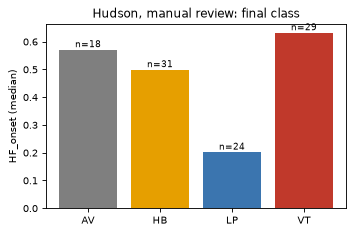

In [10]:
rev = pd.read_csv(RES / "onset_hb_lp_hudson_revision.csv")
display(rev)
fig, ax = plt.subplots(figsize=(4.5, 3))
ax.bar(rev.final, rev.HF_onset, color=[COLOR.get(c, "k") for c in rev.final])
for i, (n, v) in enumerate(zip(rev.n, rev.HF_onset)):
    ax.text(i, v + .01, f"n={n}", ha="center", fontsize=8)
ax.set_ylabel("HF_onset (median)"); ax.set_title("Hudson, manual review: final class")
fig.tight_layout()

## 4. HB/LP criterion: high frequency at the onset by SNR quartile

If the analyst separates HB from LP by the impulsive start, `HF_onset` must be higher in HB than in LP **within each SNR quartile** (this rules out that the difference is due only to SNR).

In [11]:
partes = [pd.read_csv(RES / "onset_hb_lp_hudson_resumen.csv").assign(sistema="Hudson"),
          pd.read_csv(RES / "onset_hb_lp_copahue_resumen.csv"),
          pd.read_csv(RES / "onset_hb_lp_ruiz_resumen.csv")]
o = en(pd.concat(partes, ignore_index=True))
o.pivot_table(index=["sistema", "q"], columns="label", values=["HF_onset", "n", "snr"]).round(3)

HF_onset             n            snr        
label               HB     LP     HB     LP      HB      LP
sistema     q                                              
Copahue     0    0.591  0.284  535.0  465.0   0.605   0.819
            1    0.576  0.218  504.0  496.0   3.555   3.499
            2    0.550  0.205  552.0  448.0   5.982   5.921
            3    0.605  0.216  409.0  591.0   9.048  10.703
Hudson      0    0.379  0.142   36.0  585.0   6.032   6.401
            1    0.471  0.133   45.0  575.0  10.511  10.149
            2    0.437  0.116   94.0  526.0  14.964  14.114
            3    0.439  0.098  308.0  312.0  26.070  19.741
Ruiz-Bis    0    0.626  0.814    8.0   43.0   4.196   3.760
            1    0.739  0.726    9.0   41.0   7.064   6.388
            2    0.783  0.768   18.0   32.0   9.520   9.287
            3    0.662  0.732   28.0   23.0  13.888  13.667
Ruiz-Olleta 0    0.682  0.691   88.0   38.0   5.652   4.548
            1    0.700  0.749   94.0   31.0   9.853  10.344
            2    0.663  0.698   94.0   31.0  15.844  15.801
            3    0.618  0.576   83.0   42.0  25.316  28.910

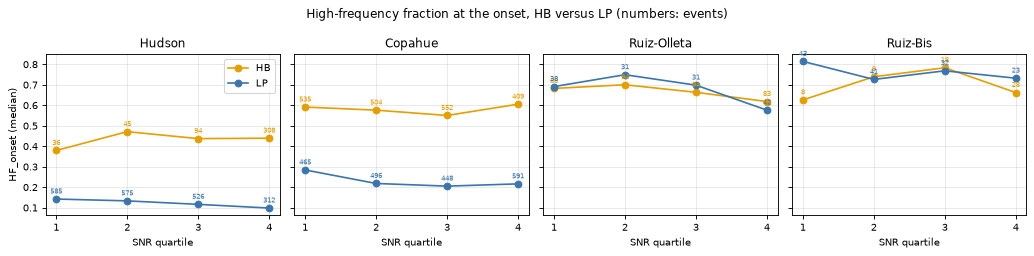

In [12]:
sist = ["Hudson", "Copahue", "Ruiz-Olleta", "Ruiz-Bis"]
fig, ejes = plt.subplots(1, 4, figsize=(13, 3.2), sharey=True)
for ax, s in zip(ejes, sist):
    g = o[o.sistema == s]
    for lab, h in g.groupby("label"):
        h = h.sort_values("q")
        ax.plot(h.q + 1, h.HF_onset, "-o", color=COLOR[lab], label=lab)
        for x, y, n in zip(h.q + 1, h.HF_onset, h.n):
            ax.annotate(str(n), (x, y), textcoords="offset points", xytext=(0, 5), fontsize=6,
                        ha="center", color=COLOR[lab])
    ax.set_title(s); ax.set_xticks([1, 2, 3, 4]); ax.set_xlabel("SNR quartile"); ax.grid(alpha=.3)
ejes[0].set_ylabel("HF_onset (median)"); ejes[0].legend()
fig.suptitle("High-frequency fraction at the onset, HB versus LP (numbers: events)")
fig.tight_layout()

In [13]:
dif = (o.pivot_table(index=["sistema", "q"], columns="label", values="HF_onset")
       .eval("HB - LP").rename("HF_onset HB − LP").unstack("q"))
dif.round(3)

q,0,1,2,3
sistema,,,,
Copahue,0.307,0.358,0.345,0.389
Hudson,0.237,0.338,0.321,0.341
Ruiz-Bis,-0.188,0.013,0.015,-0.070
Ruiz-Olleta,-0.009,-0.049,-0.035,0.042
